# Root-finding problems with JAX via optimistix

This notebook extends the approach we previously explored for initial value problems to another class of embedded numerical problem: root-finding problems.

The overall structure is very similar: inside the joint logdensity function that defines our statistical model lives a call to a library that provides a numerical solution. This time the library is [optimistix](https://docs.kidger.site/optimistix/).

In [1]:
from functools import partial
import operator

import arviz as az
import jax
import jax.numpy as jnp
import optimistix as optx
from matplotlib import pyplot as plt

from blackjax_utils import run_nuts, get_idata

In [2]:
jax.config.update("jax_enable_x64", True)

In [3]:
def fn(y, args):
    a, b = y
    c = jnp.tanh(jnp.sum(b)) - a
    d = a**2 - jnp.sinh(b + 1)
    return c, d

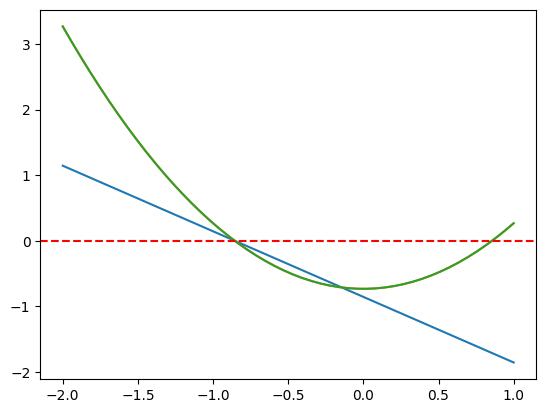

In [4]:
a_arr = jnp.linspace(-2, 1, 50)
b = jnp.array([[-0.32002086, -0.32002086], [-0.32002086, -0.32002086]])

c_arr, d_arr = jax.vmap(lambda a: fn((a, b), None))(a_arr)

f, ax = plt.subplots()
ax.plot(a_arr, c_arr);
ax.plot(a_arr, d_arr[:, 0]);
ax.axhline(0, linestyle="--", color="r");

In [5]:
solver = optx.Newton(rtol=1e-8, atol=1e-8)
y0 = (jnp.array(0.0), jnp.zeros((2, 2)))
sol = optx.root_find(fn, solver, y0)

sol

Solution(
  value=(f64[], f64[2,2]),
  result=EnumerationItem(
    _value=i32[], _enumeration=optimistix._solution.RESULTS
  ),
  aux=None,
  stats={'max_steps': 256, 'num_steps': weak_i64[]},
  state=_NewtonChordState(
    f=(f64[], f64[2,2]),
    linear_state=None,
    diff=(f64[], f64[2,2]),
    diffsize=f64[],
    diffsize_prev=weak_f64[],
    result=EnumerationItem(
      _value=i32[], _enumeration=optimistix._solution.RESULTS
    ),
    step=weak_i64[]
  )
)

In [6]:
sol.value

(Array(-0.85650715, dtype=float64),
 Array([[-0.32002086, -0.32002086],
        [-0.32002086, -0.32002086]], dtype=float64))

In [7]:
def fn_for_model(y, args):
    a, b = y
    c = jnp.tanh(jnp.sum(b)) - a + args["offset_c"]
    d = a**2 - jnp.sinh(b) + args["offset_d"]
    return c, d

def get_yhat(params, guess):
    solver = optx.Newton(rtol=1e-8, atol=1e-8)
    sol = optx.root_find(
        fn_for_model, 
        solver=solver, 
        y0=guess, 
        args=params,
        max_steps=int(1e4),
    )
    a, b = sol.value
    return a + jnp.sum(b)

def get_llik(params, data, guess):
    sigma = 0.1
    yhat = get_yhat(params, guess)
    return jax.scipy.stats.norm.logpdf(data, yhat, sigma).sum()

example_params = {"offset_c": jnp.array(0.2), "offset_d": jnp.array(-0.1)}

def get_lprior(params):
        return jax.tree.map(
            lambda x, p: jax.scipy.stats.norm.logpdf(x, p, 0.01).sum(),
            params,
            example_params,
        )


def joint_log_density(params, data, guess):
    lprior = get_lprior(params)
    lprior_sum = jax.tree.reduce(operator.add, lprior)
    llik = get_llik(params, data, guess)
    return llik + lprior_sum

def simulate(key, params, guess):
    sigma = 0.1
    yhat = get_yhat(params, guess)
    return yhat + jax.random.normal(key) * sigma

sim_key = jax.random.key(1234)
guess = (jnp.array(0.0), jnp.zeros((2, 2)))
example_sol = optx.root_find(fn_for_model, solver=solver, y0=guess, args=example_params)
example_a, example_b = example_sol.value
example_data = simulate(sim_key, example_params, guess)
joint_log_density(params=example_params, data=example_data, guess=guess)

Array(8.61020279, dtype=float64)

In [8]:
posterior_log_density = partial(joint_log_density, data=example_data, guess=guess)
key = jax.random.key(1234)
states, info = run_nuts(
    key,
    log_posterior=posterior_log_density,
    init_params=example_params,
    initial_step_size=0.0001,
    target_acceptance_rate=0.999
)
idata = get_idata(states, info)
az.summary(idata)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
offset_c,0.200,0.010,0.181,0.220,0.0,0.0,930.0,879.0,1.01
offset_d,-0.102,0.009,-0.118,-0.084,0.0,0.0,1204.0,1045.0,1.00


Note how narrow we had to make the priors, and how tightly we had to control the sampler, in order to get this to work.

This is because the Newton solver is quite fragile and doesn't really like the long trajectories it has to traverse during HMC, all using the same starting guess.

It would be nice, you might think, if there was a way to choose a new guess at each trajectory step. Well, there is! https://arxiv.org/html/2506.15423. 